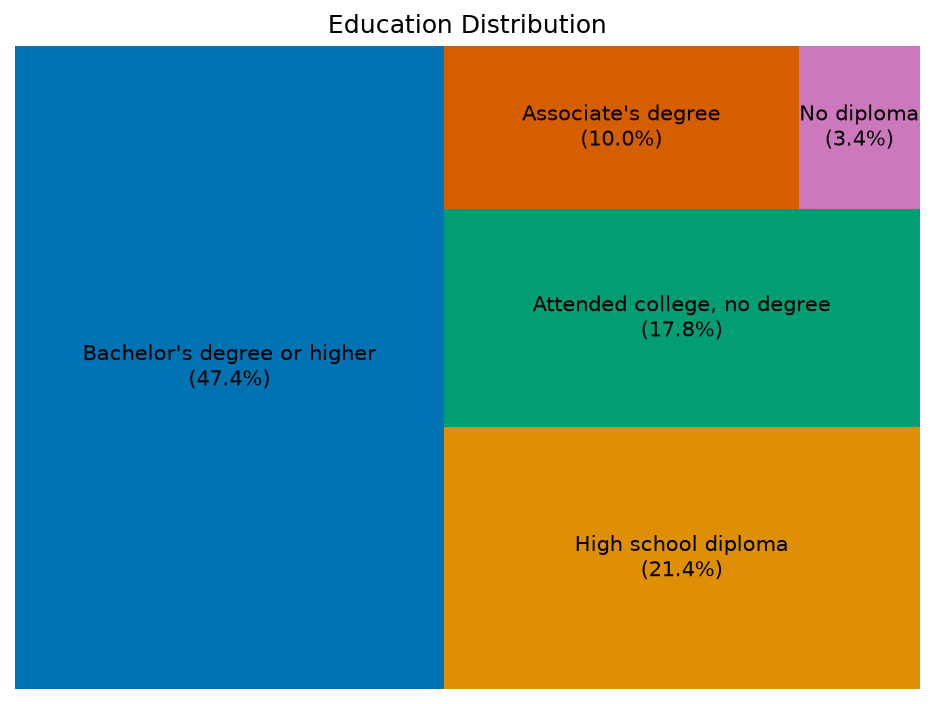

/var/folders/m7/9qp5gy9x0hdf9q3_b4dr4s100000gn/T/ipykernel_73100/2697734537.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Education', y='Annual Salary', data=data_under65,
/var/folders/m7/9qp5gy9x0hdf9q3_b4dr4s100000gn/T/ipykernel_73100/2697734537.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Education', y='Weekly hours', data=data_under65,


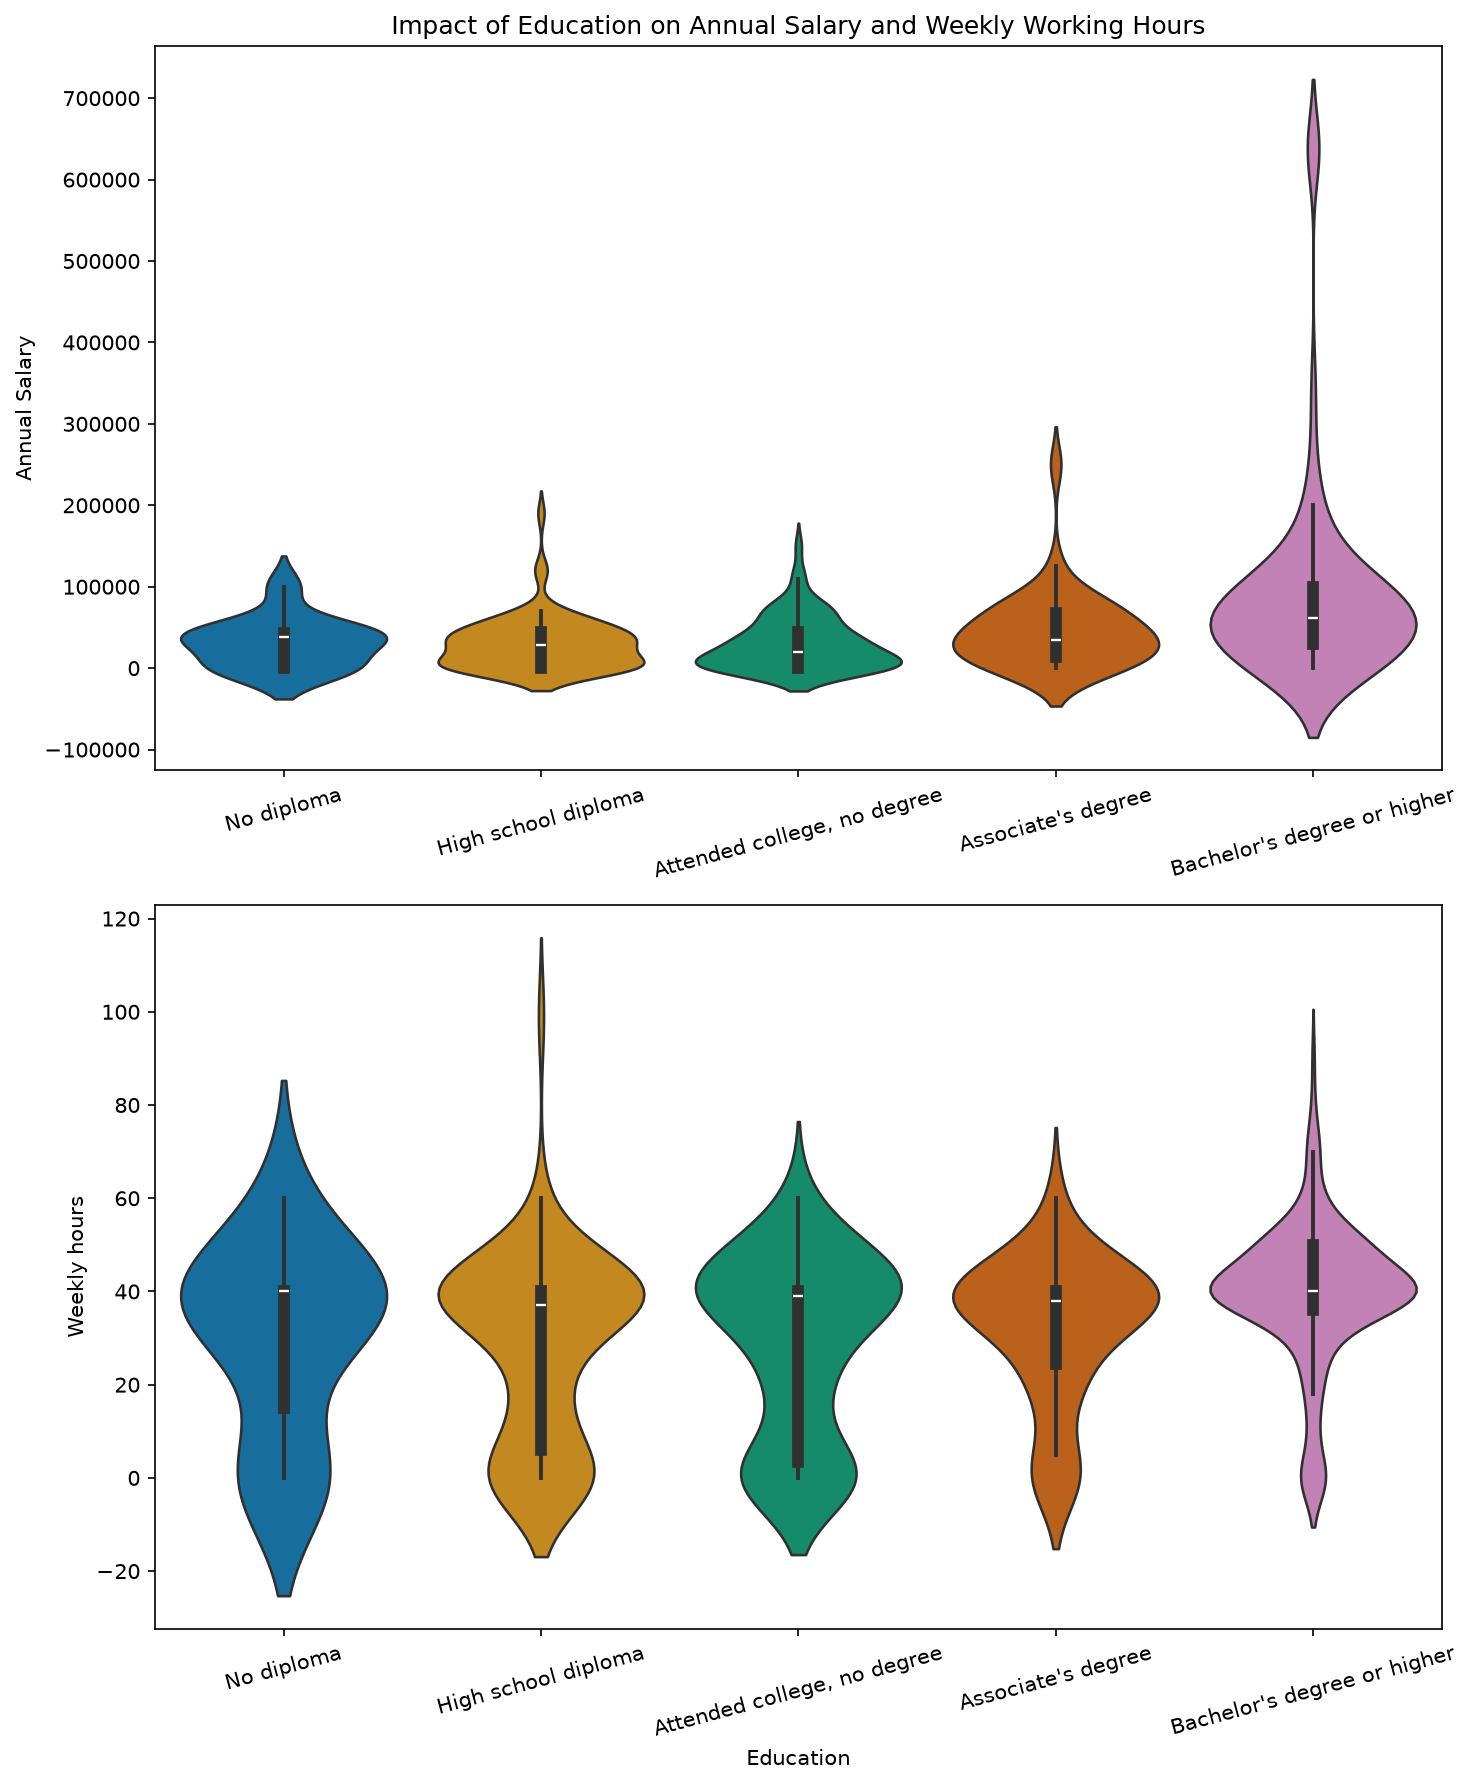

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

data = pd.read_csv("age_salary_hours.csv")

edu_counts = data['Education'].value_counts()
edu_pct = (edu_counts / edu_counts.sum() * 100).round(1)
labels = [f'{edu}\n({pct}%)' for edu, pct in zip(edu_pct.index, edu_pct.values)]

plt.figure(dpi=150)
squarify.plot(sizes=edu_counts.values,
              label=labels,
              color=sns.color_palette('colorblind', len(edu_counts)))
plt.axis('off')
plt.title('Education Distribution')
plt.tight_layout()
plt.savefig('Activity7.06_treemap.png', bbox_inches='tight')
plt.show()

data_under65 = data[data['Age'] < 65]

edu_order = ['No diploma', 'High school diploma',
             'Attended college, no degree', "Associate's degree",
             "Bachelor's degree or higher"]
edu_order = [e for e in edu_order if e in data_under65['Education'].unique()]

palette = sns.color_palette('colorblind', n_colors=len(edu_order))

fig, axes = plt.subplots(2, 1, figsize=(10, 12), dpi=150)

sns.violinplot(x='Education', y='Annual Salary', data=data_under65,
               order=edu_order, palette=palette, ax=axes[0])
axes[0].set_title('Impact of Education on Annual Salary and Weekly Working Hours')
axes[0].set_xlabel('')
axes[0].set_ylabel('Annual Salary')
axes[0].tick_params(axis='x', rotation=15)

sns.violinplot(x='Education', y='Weekly hours', data=data_under65,
               order=edu_order, palette=palette, ax=axes[1])
axes[1].set_xlabel('Education')
axes[1].set_ylabel('Weekly hours')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('Activity7.06_violin.png', bbox_inches='tight')
plt.show()